# Fetal Head Circumference (HC) and Gestational Age Estimation

Computer Vision only pipeline:

USG Image → Preprocessing → Edge Detection → Ellipse Detection → HC → GA

Tidak menggunakan Machine Learning.


In [111]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import math


In [112]:
# ==============================
# PARAMETER SETTING
# ==============================

IMAGE_PATH = "773_2HC.png"

# manual calibration
PIXEL_SIZE_MM = 0.221600823932


# CLAHE
CLAHE_CLIP = 3.0
CLAHE_GRID = (8,8)


# Median Filter
MEDIAN_KERNEL = 7


# Canny
CANNY_LOW = 70
CANNY_HIGH = 190


# Ellipse filter
MIN_MAJOR = 200
MAX_MAJOR = 800

MIN_MINOR = 150
MAX_MINOR = 700

MIN_RATIO = 1.0
MAX_RATIO = 1.6


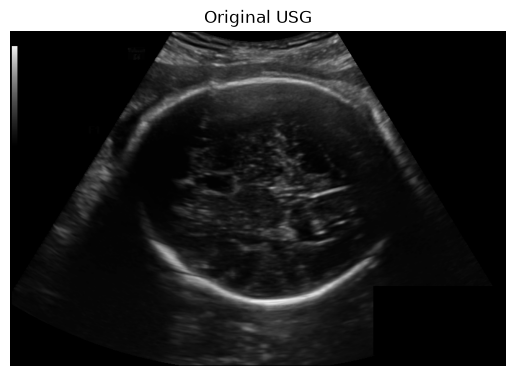

In [113]:

img = cv2.imread(IMAGE_PATH)

if img is None:
    raise FileNotFoundError("Image tidak ditemukan")

rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(rgb)
plt.title("Original USG")
plt.axis("off")
plt.show()


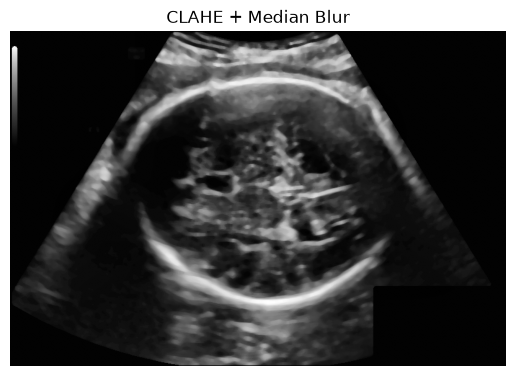

In [114]:

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

clahe = cv2.createCLAHE(
    clipLimit=CLAHE_CLIP,
    tileGridSize=CLAHE_GRID
)

enhanced = clahe.apply(gray)

blur = cv2.medianBlur(
    enhanced,
    MEDIAN_KERNEL
)

plt.imshow(blur,cmap="gray")
plt.title("CLAHE + Median Blur")
plt.axis("off")
plt.show()


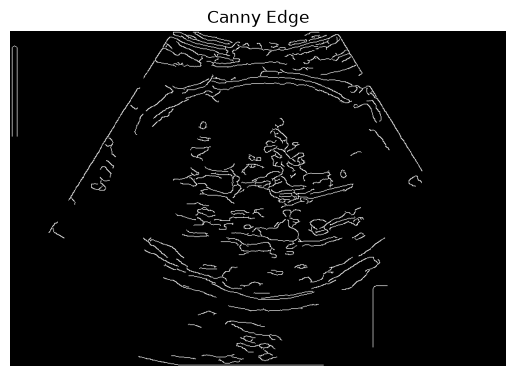

In [115]:

edges=cv2.Canny(
    blur,
    CANNY_LOW,
    CANNY_HIGH
)

plt.imshow(edges,cmap="gray")
plt.title("Canny Edge")
plt.axis("off")
plt.show()


In [116]:
# Sambungkan tepi Canny yang terfragmentasi agar kontur lebih utuh
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
edges_closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel, iterations=1)

contours,_=cv2.findContours(
    edges_closed,
    cv2.RETR_LIST,
    cv2.CHAIN_APPROX_NONE
)

candidates=[]

for cnt in contours:

    if len(cnt)>=5:

        ellipse=cv2.fitEllipse(cnt)

        major=max(ellipse[1])
        minor=min(ellipse[1])

        if minor <= 0:
            continue

        ratio=major/minor

        if (
            MIN_MAJOR < major < MAX_MAJOR
            and MIN_MINOR < minor < MAX_MINOR
            and MIN_RATIO < ratio < MAX_RATIO
        ):
            candidates.append(ellipse)


print("Candidate ellipse:",len(candidates))

if len(candidates)==0:
    ellipse = None
    print("[WARNING] Ellipse tidak ditemukan. Cek CANNY_LOW/HIGH atau parameter filter.")
else:
    ellipse=max(
        candidates,
        key=lambda e:e[1][0]*e[1][1]
    )
    print(ellipse)


Candidate ellipse: 1
((419.8154296875, 243.2310333251953), (342.0205993652344, 483.3260498046875), 89.91516876220703)


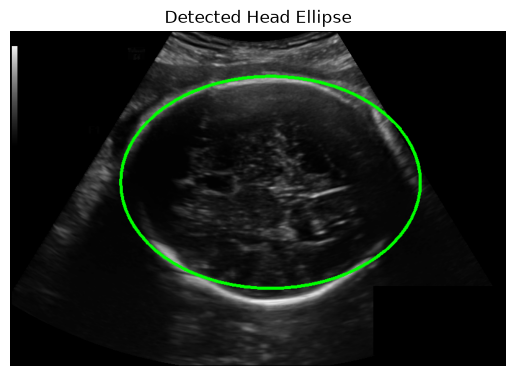

In [117]:
result=rgb.copy()

if ellipse is not None:
    cv2.ellipse(
        result,
        ellipse,
        (0,255,0),
        3
    )
    plt.imshow(result)
    plt.title("Detected Head Ellipse")
else:
    plt.imshow(result)
    plt.title("Ellipse tidak terdeteksi")
    print("[WARNING] Tidak ada ellipse untuk digambar.")

plt.axis("off")
plt.show()


In [118]:
HC_mm = None

if ellipse is not None:
    (center,axes,angle)=ellipse

    major=max(axes)/2
    minor=min(axes)/2

    a_mm=major*PIXEL_SIZE_MM
    b_mm=minor*PIXEL_SIZE_MM

    HC_mm=np.pi*(
        3*(a_mm+b_mm)
        -
        np.sqrt(
            (3*a_mm+b_mm)*(a_mm+3*b_mm)
        )
    )

    print("Semi major axis:",a_mm,"mm")
    print("Semi minor axis:",b_mm,"mm")
    print("HC:",HC_mm,"mm")
else:
    print("[WARNING] HC tidak dapat dihitung (ellipse tidak ditemukan).")


Semi major axis: 53.55272543225881 mm
Semi minor axis: 37.89602331052621 mm
HC: 289.4038820253826 mm


In [119]:
if HC_mm is not None and HC_mm > 0:

    HC=HC_mm

    log_GA=(
        0.05970*(math.log(HC)**2)
        +
        6.409e-9*(HC**3)
        +
        3.3258
    )

    GA_days=math.exp(log_GA)

    print("Estimated GA:")
    print(GA_days/7,"weeks")
else:
    print("[WARNING] GA tidak dapat dihitung (HC tidak valid).")


Estimated GA:
31.596708616656667 weeks


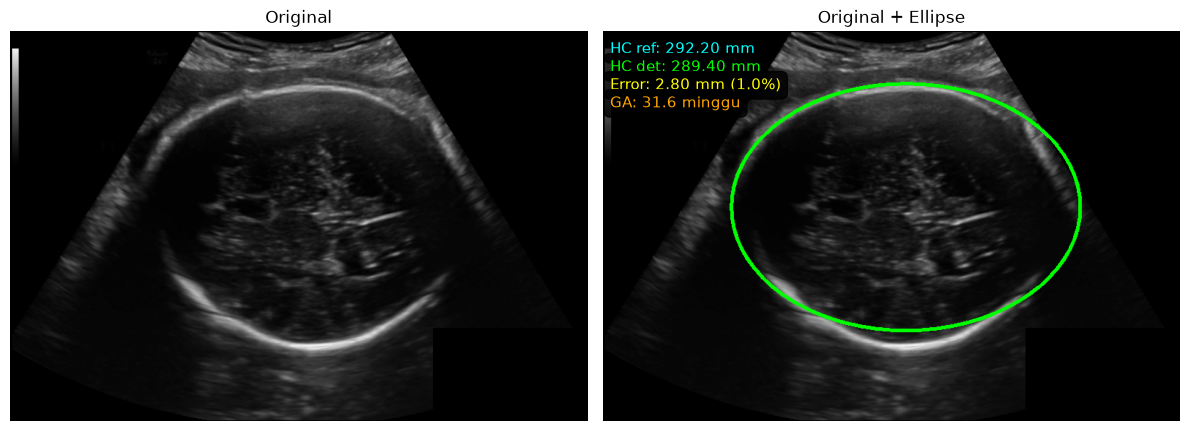

In [120]:
# Nilai acuan HC (ganti sesuai ground truth)
HC_REF_MM = 292.20

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(result)

if ellipse is not None and HC_mm is not None:
    err = abs(HC_mm - HC_REF_MM)
    err_pct = 100 * err / HC_REF_MM

    if HC_mm > 0:
        log_GA=(0.05970*(math.log(HC_mm)**2) + 6.409e-9*(HC_mm**3) + 3.3258)
        GA_weeks = math.exp(log_GA) / 7
    else:
        GA_weeks = None

    plt.text(10, 30, "HC ref: {:.2f} mm".format(HC_REF_MM),
             color="cyan", fontsize=11,
             bbox=dict(boxstyle="round,pad=0.4", facecolor="black", alpha=0.8))
    plt.text(10, 55, "HC det: {:.2f} mm".format(HC_mm),
             color="lime", fontsize=11,
             bbox=dict(boxstyle="round,pad=0.4", facecolor="black", alpha=0.8))
    plt.text(10, 80, "Error: {:.2f} mm ({:.1f}%)".format(err, err_pct),
             color="yellow", fontsize=11,
             bbox=dict(boxstyle="round,pad=0.4", facecolor="black", alpha=0.8))
    if GA_weeks is not None:
        plt.text(10, 105, "GA: {:.1f} minggu".format(GA_weeks),
                 color="orange", fontsize=11,
                 bbox=dict(boxstyle="round,pad=0.4", facecolor="black", alpha=0.8))
    plt.title("Original + Ellipse")
else:
    plt.title("Ellipse tidak terdeteksi")

plt.axis("off")

plt.tight_layout()
plt.show()
